# 5. Feature Engineering Experiments

This notebook reports the completed population-model feature experiment. The reproducible runner is `feature_experiment.py`; this notebook reads its saved outputs so the locked test set is not evaluated again.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display

THERMAL_ROOT = Path.cwd().resolve()
if THERMAL_ROOT.name == 'notebooks':
    THERMAL_ROOT = THERMAL_ROOT.parent
elif (THERMAL_ROOT / 'ai' / 'thermal_model').exists():
    THERMAL_ROOT = THERMAL_ROOT / 'ai' / 'thermal_model'
RESULTS = THERMAL_ROOT / 'results' / 'feature_engineering'
ARTIFACTS = THERMAL_ROOT / 'artifacts' / 'feature_engineering'
summary = pd.read_csv(RESULTS / 'training_oof_summary.csv')
folds = pd.read_csv(RESULTS / 'fold_metrics.csv')
per_class = pd.read_csv(RESULTS / 'training_oof_per_class.csv')
per_city = pd.read_csv(RESULTS / 'training_oof_per_city.csv')
test_results = pd.read_csv(RESULTS / 'locked_test_comparison.csv')
metadata = json.loads((ARTIFACTS / 'experiment_metadata.json').read_text())

## 5.1 Objective

Test whether alternative representations derived only from temperature and relative humidity improve three-class thermal-sensation prediction. City remains evaluation metadata. Personal calibration and medical risk prediction are out of scope.

## 5.2 Reuse Fixed Train/Test Split

The experiment reuses the existing city-and-class-stratified split (`random_state=42`): 551 training rows and 138 held-out rows. Feature/model selection uses only five-fold OOF predictions from the training rows. Exact row indices and the dataset SHA-256 are saved with the artifact.

In [2]:
display(pd.Series({
    'Training rows': metadata['train_rows'],
    'Test rows': metadata['test_rows'],
    'Random state': metadata['random_state'],
    'Dataset SHA-256': metadata['dataset_sha256'],
    'Test used for selection': metadata['selection_used_test_data'],
}).to_frame('Value'))

,Value
Training rows,551
Test rows,138
Random state,42
Dataset SHA-256,d41fb222a649ca3eb07e7f8490e47e12316c1370aa0658...
Test used for selection,False


## 5.3 V1 Original Feature Baseline

Raw `temperature_c` and `relative_humidity`. No fitted preprocessing.

## 5.4 V2 Standardisation

The same two inputs are standardised. The scaler is fitted inside each training fold.

## 5.5 V3 Polynomial Features

Temperature, humidity, temperature squared, and humidity squared. Engineering and scaling remain inside the model pipeline.

## 5.6 V4 Temperature–Humidity Interaction

V3 plus `temperature_c x relative_humidity`. This is the selected feature set.

## 5.7 V5 Derived Heat-Index/Apparent-Heat Feature

V4 plus still-air Steadman apparent temperature: `AT (C) = T + 0.33e - 4.0`, where `e (hPa) = RH/100 x 6.105 x exp(17.27T/(237.7+T))`. The omitted wind term assumes 0 m/s. This is an experimental temperature/humidity feature, not a medical-risk measure.

## 5.8 Cross-Validation / OOF Comparison

RF and XGBoost reuse the existing training-selected parameters. No additional search was run. Fold mean and standard deviation are included alongside pooled OOF metrics.

feature_set,model,macro_f1,balanced_accuracy,ordinal_mae,brier_score,warsaw_macro_f1,madrid_macro_f1,worst_city_macro_f1,warm_recall,warm_f1,cv_macro_f1_mean,cv_macro_f1_std
V1,ordinal_logistic,0.619000,0.618000,0.414000,0.475000,0.594000,0.538000,0.538000,0.484000,0.481000,0.617000,0.059000
V1,random_forest,0.623000,0.625000,0.419000,0.490000,0.549000,0.562000,0.549000,0.495000,0.499000,0.622000,0.047000
V1,xgboost,0.625000,0.625000,0.432000,0.531000,0.566000,0.587000,0.566000,0.516000,0.522000,0.623000,0.050000
V2,ordinal_logistic,0.619000,0.618000,0.414000,0.475000,0.594000,0.538000,0.538000,0.484000,0.481000,0.617000,0.059000
V2,random_forest,0.626000,0.626000,0.419000,0.490000,0.555000,0.560000,0.555000,0.505000,0.507000,0.624000,0.044000
V2,xgboost,0.625000,0.625000,0.432000,0.531000,0.566000,0.587000,0.566000,0.516000,0.522000,0.623000,0.050000
V3,ordinal_logistic,0.628000,0.627000,0.408000,0.477000,0.611000,0.536000,0.536000,0.505000,0.501000,0.627000,0.059000
V3,random_forest,0.612000,0.613000,0.434000,0.502000,0.531000,0.566000,0.531000,0.473000,0.482000,0.609000,0.060000
V3,xgboost,0.625000,0.625000,0.432000,0.531000,0.566000,0.587000,0.566000,0.516000,0.522000,0.623000,0.050000
V4,ordinal_logistic,0.631000,0.629000,0.401000,0.478000,0.616000,0.538000,0.538000,0.527000,0.509000,0.629000,0.055000


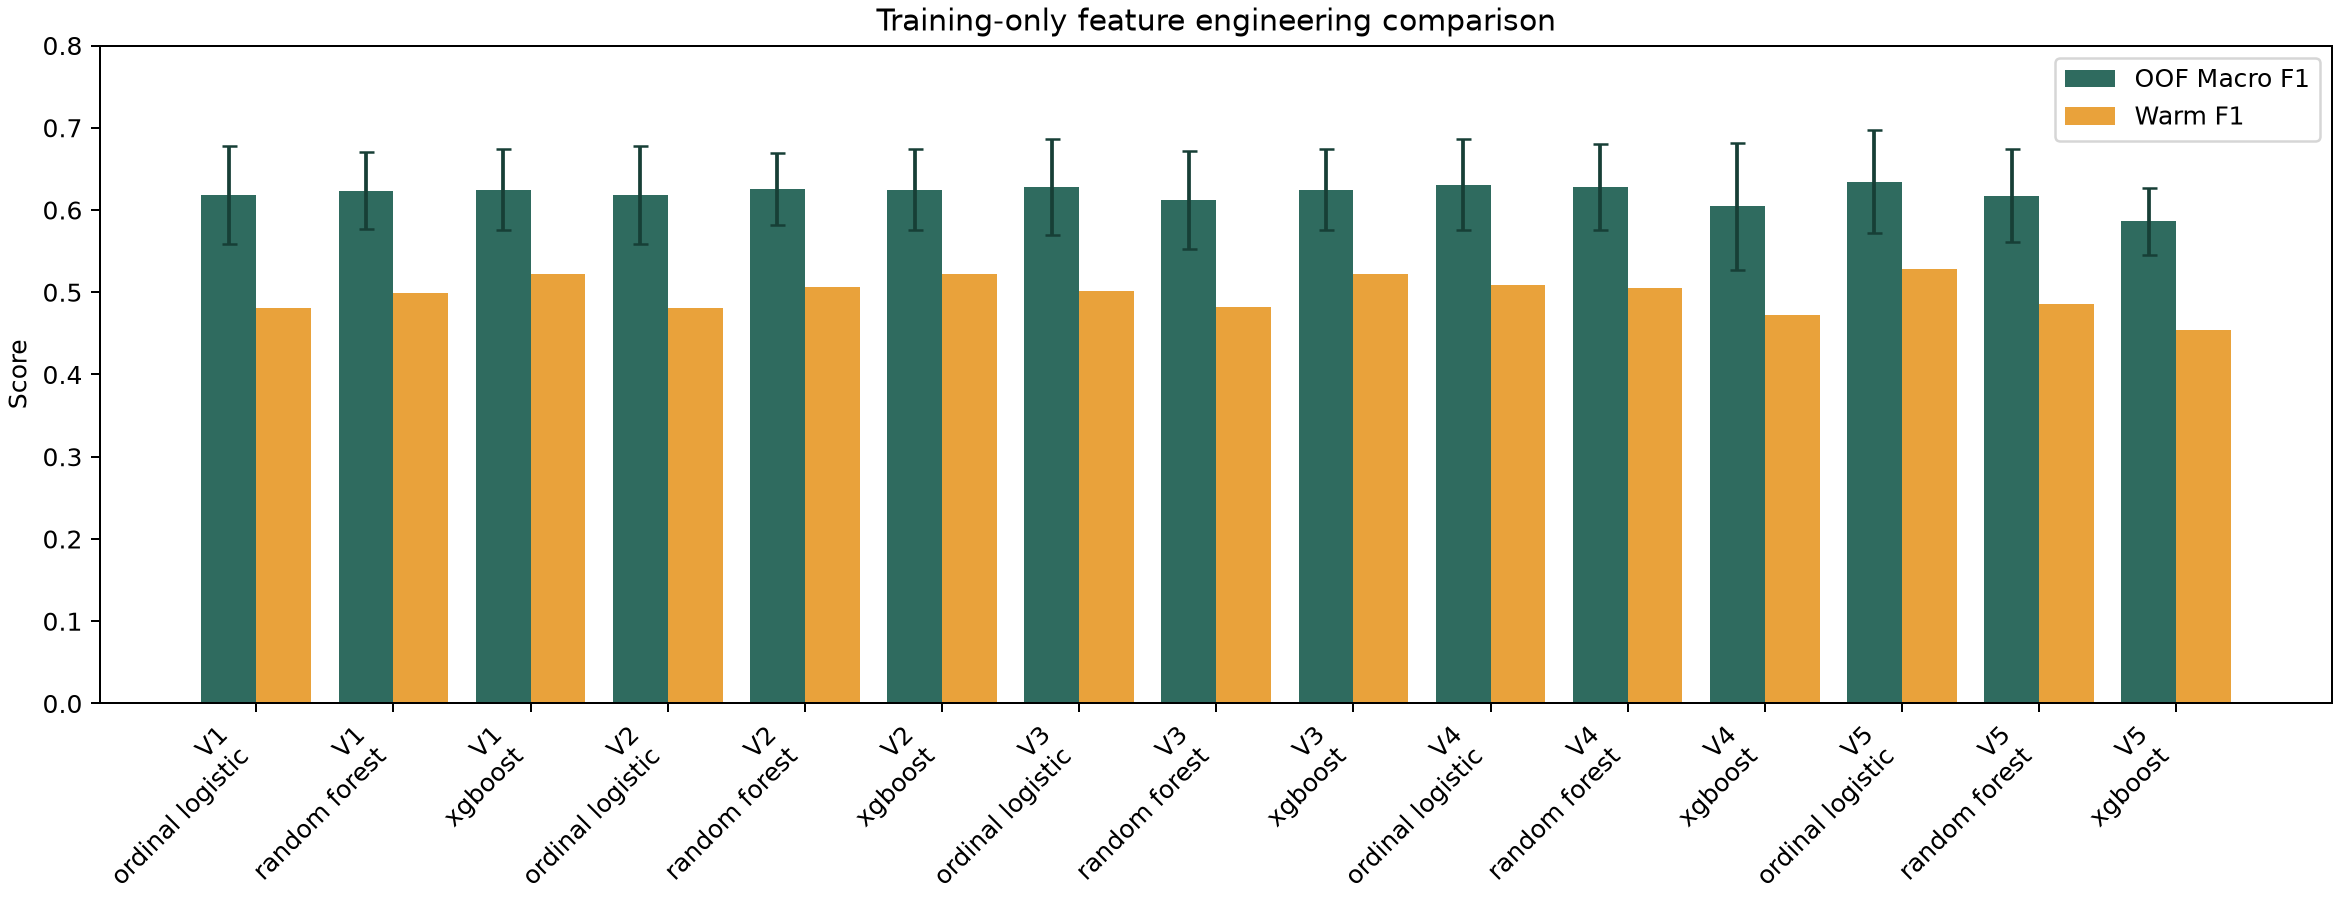

In [3]:
columns = ['feature_set', 'model', 'macro_f1', 'balanced_accuracy', 'ordinal_mae',
           'brier_score', 'warsaw_macro_f1', 'madrid_macro_f1',
           'worst_city_macro_f1', 'warm_recall', 'warm_f1',
           'cv_macro_f1_mean', 'cv_macro_f1_std']
display(summary[columns].round(3).style.hide(axis='index'))
display(Image(filename=str(RESULTS / 'training_metric_comparison.png')))

## 5.9 Per-City and Warm-Class Analysis

Warm was the weakest class in the earlier workflow, so recall and F1 are explicit decision inputs. City scores are subgroup checks, not predictive features or external-city validation.

In [4]:
selected_mask = (per_class.feature_set == 'V4') & (per_class.model == 'ordinal_logistic')
display(Markdown('### Selected configuration: per-class OOF metrics'))
display(per_class[selected_mask].round(3).style.hide(axis='index'))
display(Markdown('### Selected configuration: per-city OOF metrics'))
display(per_city[(per_city.feature_set == 'V4') & (per_city.model == 'ordinal_logistic')].round(3).style.hide(axis='index'))
display(pd.read_csv(RESULTS / 'confusion_matrices' / 'V4_ordinal_logistic.csv'))

### Selected configuration: per-class OOF metrics

feature_set,model,class_name,precision,recall,f1-score,support
V4,ordinal_logistic,OK,0.730000,0.701000,0.715000,197.000000
V4,ordinal_logistic,Warm,0.492000,0.527000,0.509000,184.000000
V4,ordinal_logistic,Too hot,0.679000,0.659000,0.669000,170.000000


### Selected configuration: per-city OOF metrics

feature_set,model,city,n,macro_f1,balanced_accuracy,ordinal_mae,brier_score
V4,ordinal_logistic,Madrid,243,0.538000,0.524000,0.461000,0.502000
V4,ordinal_logistic,Warsaw,308,0.616000,0.607000,0.354000,0.460000


,Unnamed: 0,OK,Warm,Too hot
0,OK,138,49,10
1,Warm,44,97,43
2,Too hot,7,51,112


## 5.10 Feature-Set Selection (training data only)

V4 + Ordinal Logistic was locked before test evaluation. Against V1 with the same estimator, OOF Macro F1 improved by 0.0125, balanced accuracy by 0.0108, ordinal MAE improved by 0.0127, and Warm recall/F1 improved by 0.0435/0.0281. Brier worsened by only 0.0034 and worst-city F1 was effectively unchanged (-0.0007).

The paired fold Macro F1 gain was 0.0116 with standard error 0.0071. This is a small exploratory improvement, not strong statistical significance. V5 was not selected because its gain was within paired-fold noise and it adds a still-air formula assumption.

In [5]:
display(summary.query("model == 'ordinal_logistic'")[
    ['feature_set', 'macro_f1', 'cv_macro_f1_gain_vs_v1',
     'paired_gain_standard_error', 'meaningful_gain_vs_v1',
     'warm_recall', 'warm_f1']
].round(3).style.hide(axis='index'))
display(pd.Series({
    'Selected feature set': metadata['selected_feature_set'],
    'Selected model': metadata['selected_model'],
}).to_frame('Locked choice'))

feature_set,macro_f1,cv_macro_f1_gain_vs_v1,paired_gain_standard_error,meaningful_gain_vs_v1,warm_recall,warm_f1
V1,0.619000,0.000000,0.000000,False,0.484000,0.481000
V2,0.619000,0.000000,0.000000,False,0.484000,0.481000
V3,0.628000,0.009000,0.005000,False,0.505000,0.501000
V4,0.631000,0.012000,0.007000,True,0.527000,0.509000
V5,0.634000,0.015000,0.017000,False,0.565000,0.528000


,Locked choice
Selected feature set,V4
Selected model,ordinal_logistic


## 5.11 Locked Final Test Evaluation

Only the locked V4 Ordinal Logistic pipeline was newly evaluated. The V1 Random Forest row is the stored original reference, not a new baseline test run.

In [6]:
test_columns = ['role', 'feature_set', 'model', 'macro_f1', 'balanced_accuracy',
                'ordinal_mae', 'brier_score', 'warsaw_macro_f1',
                'madrid_macro_f1', 'worst_city_macro_f1', 'warm_recall', 'warm_f1']
display(test_results[test_columns].round(3).style.hide(axis='index'))

role,feature_set,model,macro_f1,balanced_accuracy,ordinal_mae,brier_score,warsaw_macro_f1,madrid_macro_f1,worst_city_macro_f1,warm_recall,warm_f1
selected,V4,ordinal_logistic,0.638000,0.644000,0.377000,0.461000,0.540000,0.605000,0.540000,0.435000,0.465000
original_v1_reference_existing,V1,random_forest,0.628000,0.632000,0.399000,0.482000,0.517000,0.608000,0.517000,0.457000,0.472000


## 5.12 Conclusion and Limitations

V4 + Ordinal Logistic improved the locked test Macro F1 (0.638 vs 0.628), balanced accuracy, ordinal MAE, Brier, and worst-city F1 versus the stored original V1 Random Forest reference. However, test Warm recall fell from 0.457 to 0.435 and Warm F1 fell from 0.472 to 0.465. The Warm improvement seen in training OOF therefore did not generalise to the held-out sample.

The training gain is modest relative to fold variability, the dataset is small, and the held-out set was already reported by the earlier population-model workflow. V4 keeps the same two runtime inputs and adds deterministic preprocessing only; the experimental artifact does not replace the existing deployed candidate.